<a href="https://colab.research.google.com/github/swethaeng2007-creator/ML-23CSE301/blob/main/Experiment-02-Logistic-Regression/Logistic_Regression_Exercises3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [25]:
from google.colab import files

uploaded = files.upload()

Saving numiqo (1).xlsx to numiqo (1).xlsx


In [26]:
import pandas as pd

df = pd.read_excel("numiqo (1).xlsx")

df.head()

,Purchasing behaviour,Gender,Age,Time spent in online shop
0,Buy now,female,22,40
1,Buy now,female,25,23
2,Buy now,male,18,12
3,Buy now,male,45,28
4,Buy now,female,12,43


In [27]:
print(df.columns)

Index(['Purchasing behaviour', 'Gender', 'Age', 'Time spent in online shop'], dtype='object')


In [28]:
import pandas as pd
import numpy as np

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [15]:
import pandas as pd
import numpy as np

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [30]:
le = LabelEncoder()

df['Purchasing behaviour'] = le.fit_transform(df['Purchasing behaviour'])
df['Gender'] = le.fit_transform(df['Gender'])

In [31]:
X = df[['Gender', 'Age', 'Time spent in online shop']]

y = df['Purchasing behaviour']

In [32]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [33]:
model = LogisticRegression(max_iter=1000)

model.fit(X_train, y_train)

LogisticRegression(max_iter=1000)

In [34]:
y_pred = model.predict(X_test)

print(y_pred)

[1 1 1 2 1]


In [35]:
print("Accuracy :", accuracy_score(y_test, y_pred))

Accuracy : 0.4


In [36]:
print("Confusion Matrix")
print(confusion_matrix(y_test, y_pred))

Confusion Matrix
[[0 2 0]
 [0 1 0]
 [0 1 1]]


In [37]:
new_customer = pd.DataFrame({
    'Gender':[1],                # Male (or 0 if Female, depending on encoding)
    'Age':[25],
    'Time spent in online shop':[45]
})

prediction = model.predict(new_customer)

print("Predicted Purchasing Behaviour:", prediction[0])

Predicted Purchasing Behaviour: 1


                     Feature  Coefficient
0                     Gender     0.260076
1                        Age     0.007676
2  Time spent in online shop    -0.007129


<Axes: title={'center': 'Feature Importance'}, xlabel='Feature'>

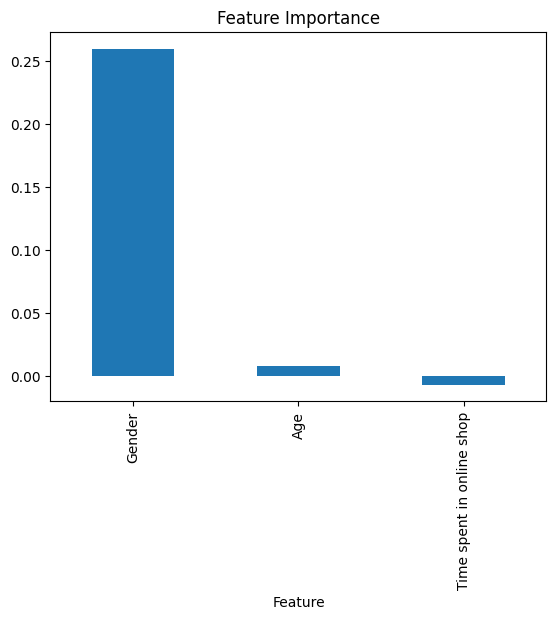

In [38]:
importance = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model.coef_[0]
})

print(importance)

importance.plot(
    x='Feature',
    y='Coefficient',
    kind='bar',
    legend=False,
    title='Feature Importance'
)